# **Connect to GEE**

In [ ]:
!pip install -q --upgrade --pre xee
!pip install -q -U geemap

In [ ]:
import ee

In [ ]:
ee.Authenticate()
ee.Initialize(
    project = 'ee-amirhosseinahrari',
    opt_url = 'https://earthengine-highvolume.googleapis.com'
)

# **Study Area**

In [ ]:
import geemap

In [ ]:
map = geemap.Map(basemap = 'SATELLITE')
map

Map(center=[0, 0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', transp…

In [ ]:
roi = map.draw_last_feature.geometry()
roi

ee.Geometry({
  "functionInvocationValue": {
    "functionName": "Feature.geometry",
    "arguments": {
      "feature": {
        "functionInvocationValue": {
          "functionName": "Feature",
          "arguments": {
            "geometry": {
              "functionInvocationValue": {
                "functionName": "GeometryConstructors.Polygon",
                "arguments": {
                  "coordinates": {
                    "constantValue": [
                      [
                        [
                          40.078125,
                          19.47695
                        ],
                        [
                          40.078125,
                          43.197167
                        ],
                        [
                          70.576172,
                          43.197167
                        ],
                        [
                          70.576172,
                          19.47695
                        ],
                        [
                          40.078125,
                          19.47695
                        ]
                      ]
                    ]
                  },
                  "geodesic": {
                    "constantValue": false
                  }
                }
              }
            }
          }
        }
      }
    }
  }
})

# **Image Collection**

In [ ]:
merra =(
    ee.ImageCollection("NASA/GSFC/MERRA/aer/2")
    .filterDate('2015','2026')
    .select(['DUSCATAU'],['aot'])
)

In [ ]:
time_start = ee.Date('2015')
time_end = ee.Date('2026')
time_diff = time_end.difference(time_start, 'month').round()
time_list = ee.List.sequence(0, ee.Number(time_diff).subtract(1)).map(
    lambda x: time_start.advance(x, 'month')
)

def monthly(date_list, col):
  start_date = ee.Date(date_list)
  end_date = start_date.advance(1, 'month')
  col_mean = col.filterDate(start_date, end_date).mean()
  return col_mean.set('system:time_start', start_date.millis())

In [ ]:
merra_monthly = ee.ImageCollection(
    time_list.map(
        lambda x: monthly(x, merra)
    )
)

In [ ]:
merra_monthly

In [ ]:
era = (
    ee.ImageCollection("ECMWF/ERA5_LAND/MONTHLY_AGGR")
    .filterDate('2015','2026')
    .select(
        'temperature_2m',
        'volumetric_soil_water_layer_1',
        'runoff_sum',
        'u_component_of_wind_10m',
        'v_component_of_wind_10m',
        'total_precipitation_sum'
    )
)

In [ ]:
era

# **to Xarray**

In [ ]:
from xee import helpers
from shapely.geometry import shape
import xarray as xr

In [ ]:
grid = helpers.fit_geometry(
    geometry = shape(roi.getInfo()),
    grid_crs ='EPSG:4326',
    grid_scale = (0.5, -0.5)
)

In [ ]:
ds_merra = xr.open_dataset(
    merra_monthly,
    engine = 'ee',
    **grid
)

In [ ]:
ds_merra = ds_merra.sortby('time') * 1

In [ ]:
ds_era = xr.open_dataset(
    era,
    engine = 'ee',
    **grid
)

In [ ]:
ds_era =ds_era.sortby('time') * 1

In [ ]:
ds = xr.merge([ds_merra, ds_era])

In [ ]:
import numpy as np

In [ ]:
ds['wind_speed'] = np.sqrt(
    ds['u_component_of_wind_10m'] ** 2 +
    ds['v_component_of_wind_10m'] ** 2
)

In [ ]:
ds = ds.drop(['u_component_of_wind_10m',
              'v_component_of_wind_10m'])

# **Clip**

In [ ]:
border =(
    ee.FeatureCollection("USDOS/LSIB_SIMPLE/2017")
    .filter(ee.Filter.eq('country_na','Iran'))
)

border

In [ ]:
border_gdf = geemap.ee_to_gdf(border)

In [ ]:
!pip install -q rioxarray
import rioxarray

In [ ]:
ds_proj = ds.rio.write_crs('EPSG:4326')

In [ ]:
ds_clip = ds_proj.rio.clip(border_gdf.geometry, border_gdf.crs)

In [ ]:
thr = ds_clip['aot'].mean('time').mean(dim = ['x','y']).item()
thr

0.12475979328155518

In [ ]:
ds_clip['aot_class'] = (ds_clip['aot'] > thr).astype(int)

In [ ]:
ds_clip = ds_clip.drop('aot')

# **Modelling**

In [ ]:
df = ds_clip.to_dataframe().dropna().drop('spatial_ref', axis = 1)

In [ ]:
x = df.drop('aot_class', axis = 1)
x

temperature_2m  volumetric_soil_water_layer_1  \
time       y     x                                                      
2015-01-01 39.25 44.25      267.841370                       0.362399   
                 44.75      274.045715                       0.390792   
                 47.25      275.911102                       0.368653   
                 47.75      276.993835                       0.381686   
           38.75 44.75      271.899994                       0.399845   
...                                ...                            ...   
2025-12-01 25.75 60.25      293.231598                       0.023097   
                 60.75      293.635040                       0.017578   
                 61.25      293.576477                       0.016627   
                 61.75      293.370667                       0.015895   
           25.25 61.25      293.758026                       0.012462   

                        runoff_sum  total_precipitation_sum  wind_speed  
time       y     x                                                       
2015-01-01 39.25 44.25    0.003512                 0.025405    0.836555  
                 44.75    0.000294                 0.021155    0.460746  
                 47.25    0.001251                 0.031054    0.233995  
                 47.75    0.000253                 0.023796    0.508889  
           38.75 44.75    0.001205                 0.041816    0.753724  
...                            ...                      ...         ...  
2025-12-01 25.75 60.25    0.000081                 0.015966    0.299314  
                 60.75    0.000072                 0.013032    0.127108  
                 61.25    0.000060                 0.012680    0.196931  
                 61.75    0.000053                 0.012360    0.328545  
           25.25 61.25    0.000069                 0.009921    0.402561  

[81972 rows x 5 columns]

In [ ]:
y = df['aot_class']
y

time        y      x    
2015-01-01  39.25  44.25    0
                   44.75    0
                   47.25    0
                   47.75    0
            38.75  44.75    0
                           ..
2025-12-01  25.75  60.25    0
                   60.75    0
                   61.25    0
                   61.75    0
            25.25  61.25    0
Name: aot_class, Length: 81972, dtype: int64

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size = 0.2, random_state = 42
)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
model = RandomForestClassifier(
    n_estimators = 100,
    random_state = 42
)

model.fit(x_train, y_train)

RandomForestClassifier(random_state=42)

In [ ]:
y_pred = model.predict_proba(x_test)[:,1]

In [ ]:
from sklearn.metrics import roc_auc_score

In [ ]:
print(roc_auc_score(y_test, y_pred))

0.9121156250481158


In [ ]:
df['aot_risk'] = model.predict_proba(df.drop('aot_class', axis = 1))[:,1]

In [ ]:
risk = df['aot_risk'].to_xarray()

In [ ]:
risk_mean = risk.mean('time')

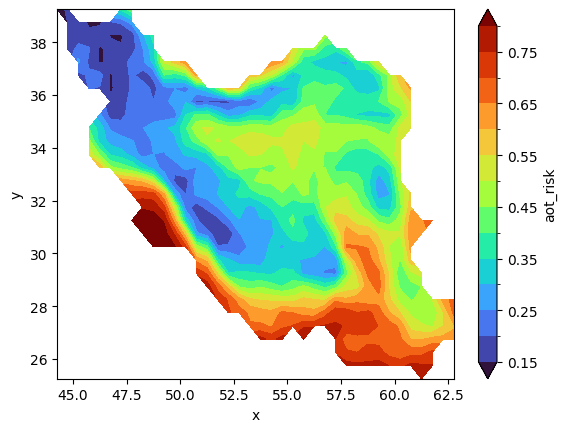

In [ ]:
risk_mean.plot.contourf(
    robust = True,
    cmap = 'turbo',
    levels = 15
)

In [ ]:
risk_month = risk.groupby('time.month').mean('time')

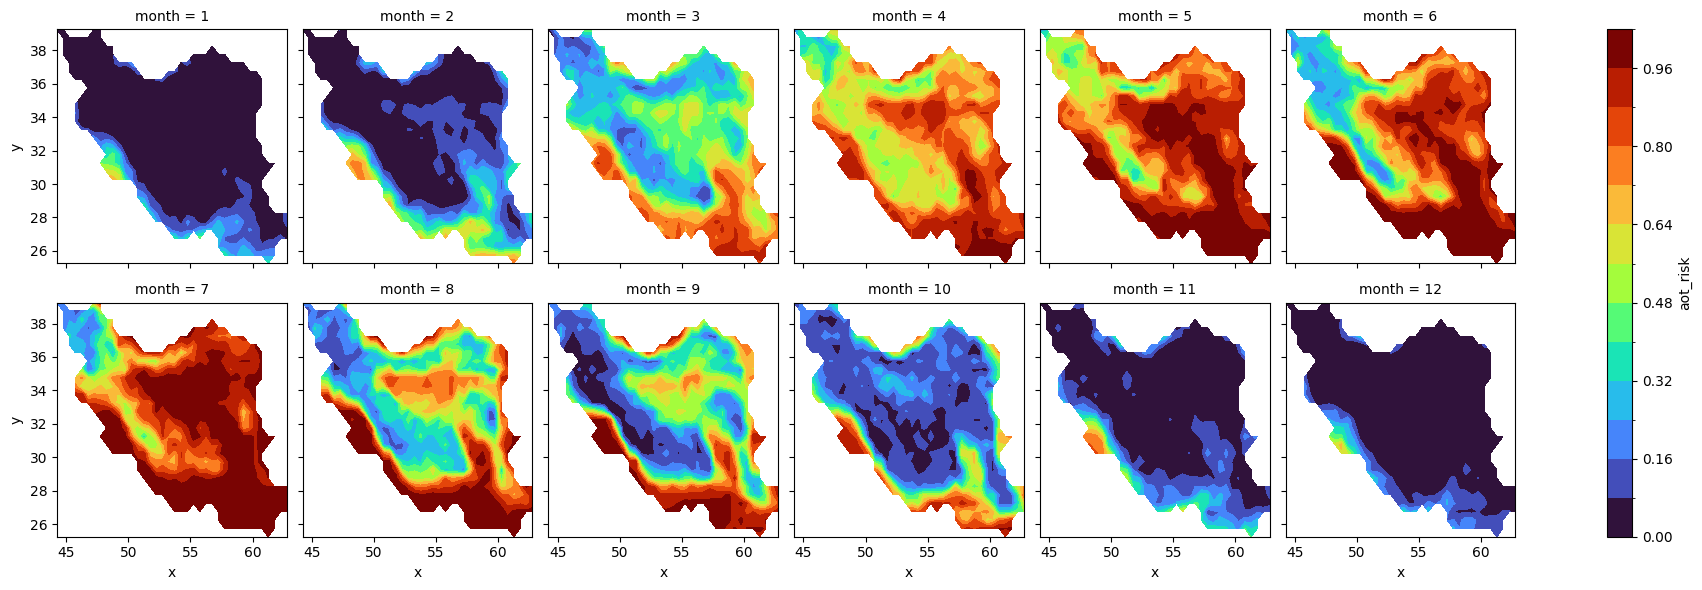

In [ ]:
risk_month.plot.contourf(
    robust = True,
    col = 'month',
    col_wrap = 6,
    cmap = 'turbo',
    levels = 15
)